# Evaluación del clasificador de intenciones

30 ejemplos escritos en este notebook: 6 por cada una de las 5 intenciones. Se carga directamente el pipeline `.joblib` y se aplica el preprocesamiento actual. No usa la API ni entrena el modelo.

Esta evaluación pequeña mide clasificación de intención, no la calidad completa del chatbot ni la clasificación de imágenes. Algunos casos ya se usaron para detectar errores; los resultados son de diagnóstico, no de una prueba independiente final.

In [1]:
from pathlib import Path
import sys
from collections import Counter
import joblib
from sklearn.metrics import (
    classification_report, precision_score, recall_score,
    f1_score, confusion_matrix,
)

# Funciona al abrir el notebook desde la raíz del proyecto.
RAIZ = Path.cwd()
if not (RAIZ / "artifacts" / "nlp_intenciones.joblib").exists():
    raise FileNotFoundError("Abre este notebook desde la carpeta Chatbot_intenciones_reglas")
sys.path.insert(0, str(RAIZ))
from nlp_preprocessing import preparar_texto

modelo = joblib.load(RAIZ / "artifacts" / "nlp_intenciones.joblib")
clases = modelo.classes_.tolist()
print("Clases:", clases)


Clases: ['consultar_ejecucion', 'consultar_promocion', 'consultar_vigencia', 'despedida', 'saludo']


## 1. Ejemplos y etiquetas esperadas

Las etiquetas se fijan antes de ejecutar el modelo. No deben cambiarse para acomodar sus predicciones.

In [2]:
casos = [
    ("Hola, vengo a consultar las frutas", "saludo"),
    ("Buenos días, asistente de frutas", "saludo"),
    ("Buenas tardes, necesito orientación", "saludo"),
    ("Qué tal, asistente retail", "saludo"),
    ("Hola, ¿me orientas por favor?", "saludo"),
    ("Saludos, quiero hacerte una consulta", "saludo"),

    ("Muchas gracias, hasta pronto", "despedida"),
    ("Gracias, con eso termino mi consulta", "despedida"),
    ("Adiós, que tengas bonita tarde", "despedida"),
    ("Hasta luego, asistente retail", "despedida"),
    ("Gracias por orientarme hoy", "despedida"),
    ("Nos vemos, gracias por la atención", "despedida"),

    ("Qué descuento ofrecen en manzana verde", "consultar_promocion"),
    ("Me puedes indicar la oferta de Royal Gala", "consultar_promocion"),
    ("Cuál es la promoción para las naranjas", "consultar_promocion"),
    ("Qué descuento corresponde a las mandarinas", "consultar_promocion"),
    ("que promo tiene la granny smith", "consultar_promocion"),
    ("Dime qué descuento tiene Orange", "consultar_promocion"),

    ("Dónde debo exhibir la manzana verde", "consultar_ejecucion"),
    ("Qué exhibición corresponde a Royal Gala", "consultar_ejecucion"),
    ("Cómo debo colocar las naranjas en tienda", "consultar_ejecucion"),
    ("Qué material de exhibición necesitan las mandarinas", "consultar_ejecucion"),
    ("Qué mueble necesita Granny Smith", "consultar_ejecucion"),
    ("Cómo debe ser la ejecución de la manzana gala", "consultar_ejecucion"),

    ("Hasta qué fecha dura el descuento de manzana verde", "consultar_vigencia"),
    ("Cuándo finaliza la oferta de Royal Gala", "consultar_vigencia"),
    ("Cuándo inicia la promoción de las naranjas", "consultar_vigencia"),
    ("Cuál es la vigencia de las mandarinas", "consultar_vigencia"),
    ("cuándo termina la promo de granny smith", "consultar_vigencia"),
    ("Qué fechas cubre la oferta de Satsumas", "consultar_vigencia"),
]
assert len(casos) == 30
assert Counter(etiqueta for _, etiqueta in casos) == {clase: 6 for clase in clases}
print("Total:", len(casos))
print("Ejemplos por intención:", dict(Counter(etiqueta for _, etiqueta in casos)))


Total: 30
Ejemplos por intención: {'saludo': 6, 'despedida': 6, 'consultar_promocion': 6, 'consultar_ejecucion': 6, 'consultar_vigencia': 6}


## 2. Predicciones directas

El `.joblib` contiene el vectorizador y el SVM. La limpieza y el stemming se aplican antes de llamar a `predict`, igual que en la aplicación.

In [3]:
textos = [texto for texto, _ in casos]
y_real = [etiqueta for _, etiqueta in casos]
textos_procesados = [preparar_texto(texto) for texto in textos]
y_pred = modelo.predict(textos_procesados)

for numero, ((texto, real), predicha) in enumerate(zip(casos, y_pred), start=1):
    resultado = "OK" if real == predicha else "ERROR"
    print(f"{numero:02}. [{resultado}] {texto}")
    print(f"    Esperada: {real} | Predicha: {predicha}")


01. [OK] Hola, vengo a consultar las frutas
    Esperada: saludo | Predicha: saludo
02. [OK] Buenos días, asistente de frutas
    Esperada: saludo | Predicha: saludo
03. [OK] Buenas tardes, necesito orientación
    Esperada: saludo | Predicha: saludo
04. [OK] Qué tal, asistente retail
    Esperada: saludo | Predicha: saludo
05. [OK] Hola, ¿me orientas por favor?
    Esperada: saludo | Predicha: saludo
06. [OK] Saludos, quiero hacerte una consulta
    Esperada: saludo | Predicha: saludo
07. [OK] Muchas gracias, hasta pronto
    Esperada: despedida | Predicha: despedida
08. [OK] Gracias, con eso termino mi consulta
    Esperada: despedida | Predicha: despedida
09. [OK] Adiós, que tengas bonita tarde
    Esperada: despedida | Predicha: despedida
10. [OK] Hasta luego, asistente retail
    Esperada: despedida | Predicha: despedida
11. [OK] Gracias por orientarme hoy
    Esperada: despedida | Predicha: despedida
12. [OK] Nos vemos, gracias por la atención
    Esperada: despedida | Predicha: 

## 3. Precision, recall y F1

**Precision:** de lo que el modelo asignó a una clase, cuánto acertó. **Recall:** de los ejemplos reales de una clase, cuántos encontró. **F1:** combina precision y recall.

Se muestran valores por intención y el promedio **macro**, que da el mismo peso a cada clase. `support` indica cuántos ejemplos reales tiene cada clase.

In [4]:
print(classification_report(
    y_real, y_pred, labels=clases, target_names=clases,
    digits=4, zero_division=0,
))
print("Promedios macro")
print(f"Precision: {precision_score(y_real, y_pred, average='macro', zero_division=0):.2%}")
print(f"Recall:    {recall_score(y_real, y_pred, average='macro', zero_division=0):.2%}")
print(f"F1:        {f1_score(y_real, y_pred, average='macro', zero_division=0):.2%}")


                     precision    recall  f1-score   support

consultar_ejecucion     1.0000    0.8333    0.9091         6
consultar_promocion     0.8571    1.0000    0.9231         6
 consultar_vigencia     1.0000    0.8333    0.9091         6
          despedida     0.8571    1.0000    0.9231         6
             saludo     1.0000    1.0000    1.0000         6

           accuracy                         0.9333        30
          macro avg     0.9429    0.9333    0.9329        30
       weighted avg     0.9429    0.9333    0.9329        30

Promedios macro
Precision: 94.29%
Recall:    93.33%
F1:        93.29%


## 4. Matriz de confusión con Seaborn

Las filas muestran las intenciones reales y las columnas las predicciones. La diagonal contiene los aciertos; las demás celdas muestran las confusiones. Cada número indica la cantidad de ejemplos.


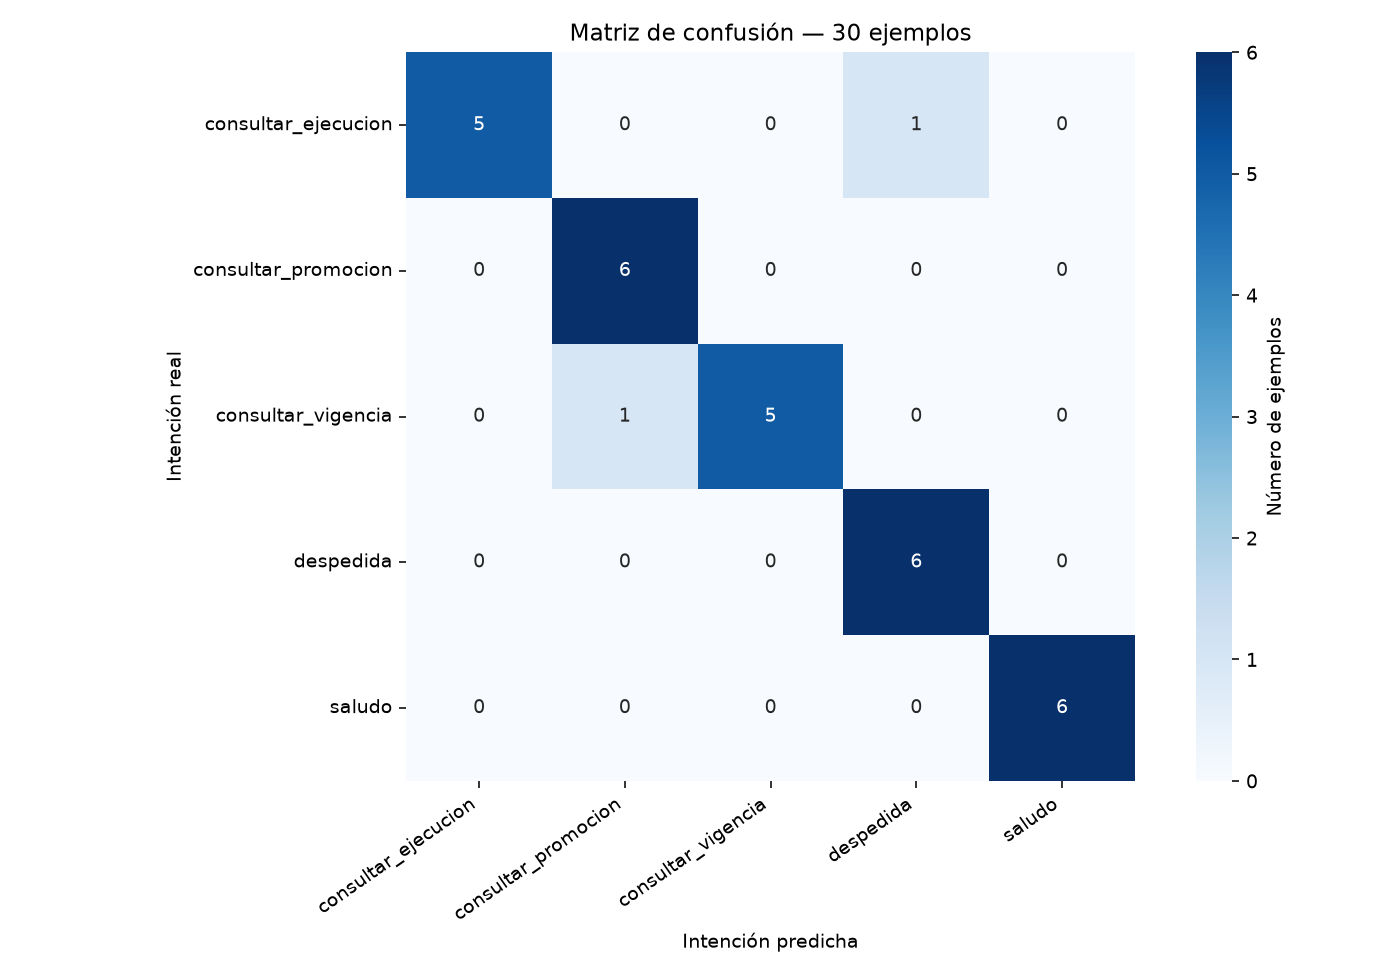

In [5]:
import seaborn as sns
import matplotlib.pyplot as plt

matriz = confusion_matrix(y_real, y_pred, labels=clases)
fig, ax = plt.subplots(figsize=(10, 7))
sns.heatmap(
    matriz, annot=True, fmt="d", cmap="Blues",
    xticklabels=clases, yticklabels=clases,
    vmin=0, vmax=6, square=True,
    cbar_kws={"label": "Número de ejemplos"}, ax=ax,
)
ax.set_title("Matriz de confusión — 30 ejemplos")
ax.set_xlabel("Intención predicha")
ax.set_ylabel("Intención real")
plt.setp(ax.get_xticklabels(), rotation=35, ha="right")
plt.setp(ax.get_yticklabels(), rotation=0)
fig.tight_layout()
plt.show()


## 5. Errores para revisar

No se corrige ni reentrena el modelo desde este notebook. Si usamos estos errores para ajustarlo, necesitamos nuevas consultas para una evaluación independiente posterior.

In [6]:
errores = [(texto, real, str(predicha))
           for (texto, real), predicha in zip(casos, y_pred)
           if real != predicha]
print(f"Errores: {len(errores)} de {len(casos)}")
for texto, real, predicha in errores:
    print(f"\nConsulta: {texto}\nEsperada: {real}\nPredicha: {predicha}")


Errores: 2 de 30

Consulta: Qué mueble necesita Granny Smith
Esperada: consultar_ejecucion
Predicha: despedida

Consulta: Qué fechas cubre la oferta de Satsumas
Esperada: consultar_vigencia
Predicha: consultar_promocion
